# INSTITUTO Univeridad Autonoma del Estado de Mexico Centro Universitario UAEM Zumpango
**Asignatura:** Investigación de Operaciones
**Práctica 1:** Implementación de Modelos de Investigación de 
Operaciones mediante Python y Jupyter Notebook
**Integrantes:** 
- Alexis Yahir Alvarez Leon, Ariadna Abigail Alanis, Estrada, Jose Antonio Rodriguez Estudillo
**Fecha:** 12/11/26

## 1. Descripción y Planteamiento del Problema (Enfoque TI)
Una empresa de desarrollo de software necesita conectar **8 servidores** (nodos del 1 al 8) en su nuevo centro de datos. El costo del cableado de fibra óptica varía dependiendo de la distancia y dificultad de instalación entre cada par de servidores. 

El objetivo es determinar la red de cableado más económica posible que conecte a todos los servidores sin crear ciclos (bucles), garantizando que todos tengan conectividad. Esto se resolverá utilizando el **Algoritmo de Prim** para encontrar el Árbol de Expansión Mínima (MST).

## 2. Formulación Matemática
- **Conjunto de Nodos (V):** Servidores {1, 2, 3, 4, 5, 6, 7, 8}
- **Conjunto de Aristas (E):** Posibles conexiones entre servidores.
- **Variable de decisión:** \(x_{ij} = 1\) si se instala el cable entre el servidor \(i\) y \(j\), \(0\) en caso contrario.
- **Función Objetivo:** Minimizar el costo total del cableado.
  \[
Min Z = \sum_{(i,j) \in E} c_{ij} x_{ij}
\]
  Donde \(c_{ij}\) es el costo de conectar el servidor \(i\) con el \(j\).
- **Restricciones:** El grafo resultante debe ser conexo y tener exactamente \(n-1\) aristas (7 aristas para 8 nodos) para evitar ciclos.

In [2]:
# Importación de bibliotecas requeridas
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.sparse.csgraph import minimum_spanning_tree # Para cumplir con SciPy

# Definimos los datos de la red (Nodos y costos simulados)
datos_red = [
    (1, 2, 4), (1, 3, 6), (2, 3, 2), (2, 4, 5),
    (3, 4, 8), (3, 5, 7), (4, 5, 3), (4, 6, 9),
    (5, 6, 4), (5, 7, 6), (6, 7, 2), (6, 8, 5), (7, 8, 3)
]

# Creamos el grafo original
G = nx.Graph()
G.add_weighted_edges_from(datos_red)

# Posiciones fijas para que las gráficas se vean ordenadas
pos = nx.spring_layout(G, seed=42)

print("Librerías cargadas y red de 8 servidores definida correctamente.")

Librerías cargadas y red de 8 servidores definida correctamente.


## 3. Desarrollo del Algoritmo Paso a Paso
### Paso 0: Visualización de la Red Original
A continuación, mostramos cómo están conectados originalmente los servidores y los costos de cada posible cable.

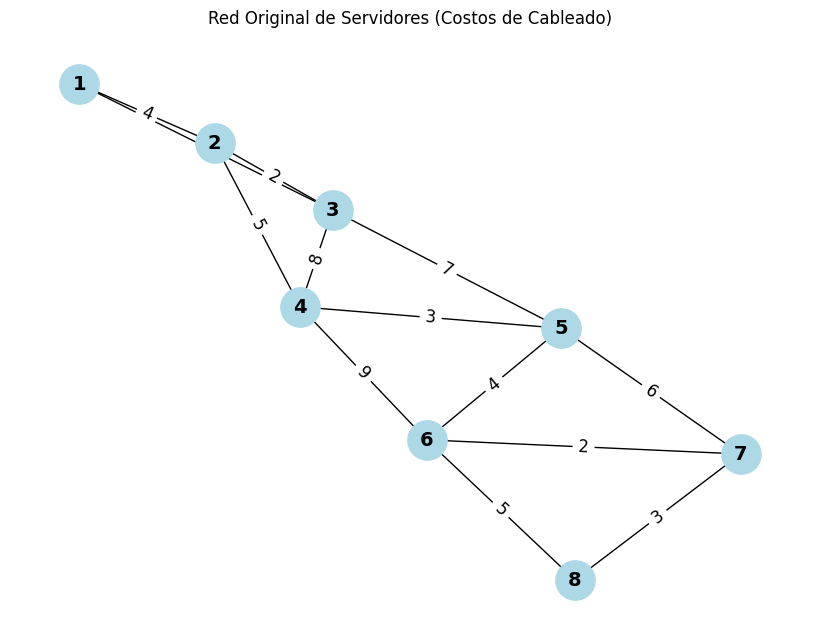

In [3]:
plt.figure(figsize=(8, 6))
# Dibujar nodos y aristas
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=800, font_weight='bold', font_size=14)
# Dibujar los pesos (costos)
etiquetas = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=etiquetas, font_size=12)

plt.title("Red Original de Servidores (Costos de Cableado)")
plt.axis('off')
plt.show()

### Pasos 1 al 7: Construcción del Árbol de Expansión Mínima
El algoritmo de Prim busca siempre la conexión más barata sin formar ciclos. A continuación, el código ejecuta el algoritmo y **genera una gráfica por cada arista que se agrega**, evidenciando el paso a paso tal como se hace a mano.

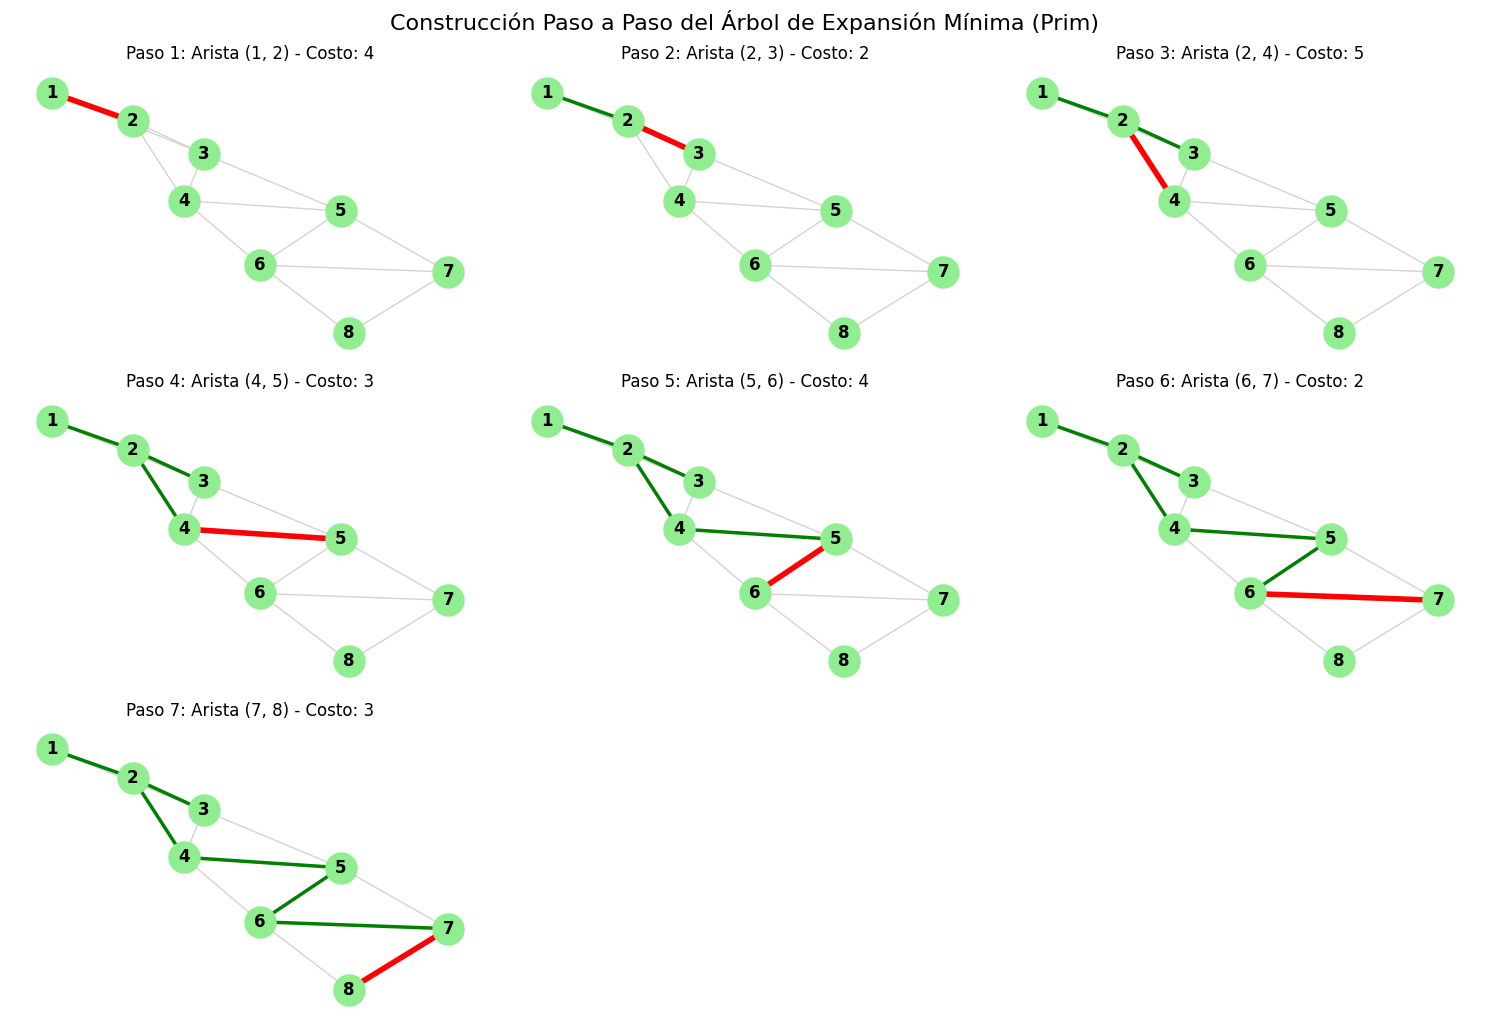

In [4]:
# Calculamos el MST (Árbol de Expansión Mínima)
mst = nx.minimum_spanning_tree(G, algorithm='prim')
aristas_mst = list(mst.edges(data=True))
costo_total = 0

# Configuramos una cuadrícula para poner las gráficas
fig = plt.figure(figsize=(15, 10))

for i, (u, v, data) in enumerate(aristas_mst, start=1):
    costo_total += data['weight']
    
    # Creamos un subgrafo con las aristas agregadas hasta el momento
    subgrafo = nx.Graph()
    subgrafo.add_nodes_from(mst.nodes())
    subgrafo.add_edges_from([(a, b) for a, b, c in aristas_mst[:i]])
    
    # Crear la subtrama
    plt.subplot(3, 3, i)
    
    # Red original en gris de fondo
    nx.draw(G, pos, with_labels=False, edge_color='lightgray', node_size=300)
    
    # Red construida hasta el paso actual (Verde)
    nx.draw(subgrafo, pos, with_labels=True, node_color='lightgreen', node_size=500, 
            edge_color='green', width=2.5, font_weight='bold')
    
    # Resaltar en rojo la arista que se acaba de agregar
    nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], edge_color='red', width=4)
    
    plt.title(f"Paso {i}: Arista ({u}, {v}) - Costo: {data['weight']}")

plt.tight_layout()
plt.suptitle("Construcción Paso a Paso del Árbol de Expansión Mínima (Prim)", fontsize=16, y=1.02)
plt.show()

### Resultado Final y Costo Mínimo
Ahora imprimimos la tabla de conexiones seleccionadas y el costo total mínimo del cableado.

--- TABLA DE CONEXIONES ÓPTIMAS ---


,Servidor Origen,Servidor Destino,Costo de Cable
0,1,2,4
1,2,3,2
2,2,4,5
3,4,5,3
4,5,6,4
5,6,7,2
6,7,8,3



 COSTO MÍNIMO TOTAL DE CABLEADO: 23


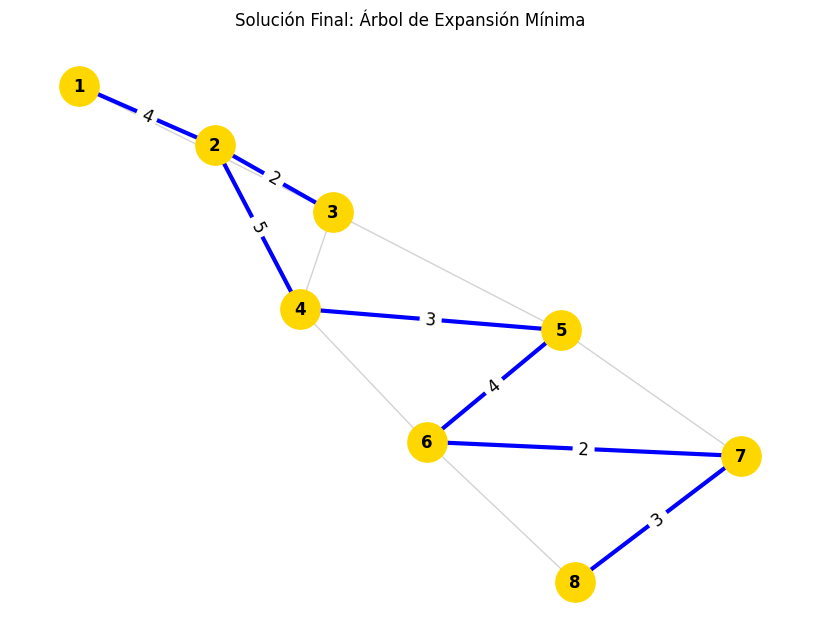

In [5]:
# Mostrar tabla de resultados con Pandas
df_resultados = pd.DataFrame([(u, v, d['weight']) for u, v, d in aristas_mst], 
                             columns=['Servidor Origen', 'Servidor Destino', 'Costo de Cable'])
print("--- TABLA DE CONEXIONES ÓPTIMAS ---")
display(df_resultados)
print(f"\n COSTO MÍNIMO TOTAL DE CABLEADO: {costo_total}")

# Gráfica de la solución final
plt.figure(figsize=(8, 6))
nx.draw(G, pos, with_labels=False, edge_color='lightgray', node_size=300)
nx.draw(mst, pos, with_labels=True, node_color='gold', node_size=800, 
        edge_color='blue', width=3, font_weight='bold')
nx.draw_networkx_edge_labels(mst, pos, edge_labels=nx.get_edge_attributes(mst, 'weight'), font_size=12)
plt.title("Solución Final: Árbol de Expansión Mínima")
plt.axis('off')
plt.show()

## 4. Interpretación de Resultados
El Algoritmo de Prim nos permitió seleccionar las 7 conexiones más económicas sin generar ciclos. Al conectar los 8 servidores con el costo mínimo, la empresa ahorra dinero en infraestructura de red. Cualquier otra combinación de cables resultaría en un gasto mayor.

## 5. Conclusiones
**Ariadna Abigail**:
Ver las gráficas de cada paso deja muy claro cómo se va armando la red sin hacer ciclos. Es un método muy práctico para calcular el cableado de los servidores sin gastar de más.

**Jose Antonio**:
El código en Python agiliza bastante el diseño de la red. Aplicarlo de esta forma evita errores al conectar los nodos y asegura que se elija siempre el costo más bajo.



**Alexis:** Aprendí a implementar NetworkX en Python para resolver problemas de optimización de redes, dándome cuenta de que es mucho más rápido que hacerlo a mano y reduce el margen de error.